In [42]:
# Librerías principales
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from matplotlib import pyplot as plt, tri
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import Dataset
from torchvision import datasets, transforms



In [43]:
# Parámetros del experimento
SEED = 1
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1.0
SCHEDULER_STEP_SIZE = 1
SCHEDULER_GAMMA = 0.7

# Directorios de trabajo
DATA_DIR = Path('./MNIST_DEPP')
OUTPUT_DIR = Path('./resultados_mnist_convnet_deep')
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
FIGURE_DIR = OUTPUT_DIR / 'figuras'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Fijamos la semilla para hacer el experimento más reproducible
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección automática del dispositivo
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo utilizado: {DEVICE}')


config = {
    'seed': SEED,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'scheduler_step_size': SCHEDULER_STEP_SIZE,
    'scheduler_gamma': SCHEDULER_GAMMA,
    'device': str(DEVICE),
}

with open(OUTPUT_DIR / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

Dispositivo utilizado: cuda


In [44]:
train_dataset = datasets.MNIST(root=DATA_DIR, train=True, transform=transforms.ToTensor(), download=True)
test_dataset = datasets.MNIST(root=DATA_DIR, train=False, transform=transforms.ToTensor(), download=True)


train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


print("Train/Test", train_dataset.data.shape, test_dataset.targets.shape)


Train/Test torch.Size([60000, 28, 28]) torch.Size([10000])


938
64


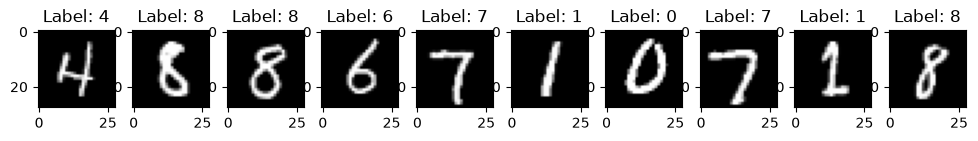

<Figure size 640x480 with 0 Axes>

In [45]:
(images, labels ) = next(iter(train_dataloader))

print(len(train_dataloader))
print(len(images))


figs, axs  =plt.subplots(1, 10, figsize=(12, 1))
axs = axs.ravel()

for  i in  range(10):
    axs[i].imshow(images[i].squeeze(), cmap='gray')
    axs[i].set_title(f'Label: {labels[i]}')

plt.show()
plt.savefig(OUTPUT_DIR/ 'figuras_mnis.png')



In [46]:
class Net(nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=0)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0)

        self.dropout1 = nn.Dropout(p=0.25)
        self.dropout2 = nn.Dropout(p=0.50)

        self.fc1 = nn.Linear(in_features=9216, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=10)

    def forward(self, X):

        #Primera conmvoluicion
        x = self.conv1(X)
        x = F.relu(x)

        #Segunda convolucion
        x = self.conv2(x)
        x = F.relu(x)

        #Reducimos dimensionalidad
        x = F.max_pool2d(x, kernel_size=2)

        #Apagamos neuronas para evitar sobreaprendizaje
        x  = self.dropout1(x)

        #Falttern
        x = torch.flatten(x, 1)

        #Linear 1
        x = self.fc1(x)
        x = F.relu(x)

        x = self.dropout2(x)

        #Linear 2
        x = self.fc2(x)

        output = F.log_softmax(x, dim=1)

        return output


modelo = Net()
modelo.to(DEVICE)
print(modelo)


with open(OUTPUT_DIR / 'modelo.pth', 'wb') as f:
    torch.save(modelo,f)


with open(OUTPUT_DIR / 'modelo.txt', 'w') as f:
    f.write(str(modelo))


Net(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (dropout1): Dropout(p=0.25, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=9216, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [47]:
def train_one_epoch(model, device, train_loader, optimizer, epoch):
    model.train()
    running_loss = 0.0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 100 == 99:
            print(f'Epoch [{epoch+1}/{EPOCHS}], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {running_loss/100:.3f}')

    return running_loss / len(train_loader)

In [48]:

def evaluate(model, device, test_loader):
    """Evalúa el modelo sobre el conjunto de test."""
    model.eval()
    test_loss = 0.0
    correct = 0

    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)

            output = model(data)

            test_loss += F.nll_loss(output, target, reduction='sum').item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = correct / len(test_loader.dataset)

    print(
        f'Test set: Average loss: {test_loss:.4f}, '
        f'Accuracy: {correct}/{len(test_loader.dataset)} ({100.0 * accuracy:.2f}%)'
    )

    return test_loss, accuracy

In [49]:
optimizer = optim.Adadelta(modelo.parameters(), lr=LEARNING_RATE)
scheduler = StepLR(optimizer, step_size=SCHEDULER_STEP_SIZE, gamma=SCHEDULER_GAMMA)

history = []

for epoch in range(1, EPOCHS + 1):
    print(f'\nÉpoca {epoch}/{EPOCHS}')

    train_loss = train_one_epoch(modelo, DEVICE, train_dataloader, optimizer, epoch)
    test_loss, test_accuracy = evaluate(modelo, DEVICE, test_dataloader)

    current_lr = scheduler.get_last_lr()[0]
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'learning_rate': current_lr,
    })

    checkpoint = {
        'epoch': epoch,
        'model_state_dict': modelo.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'history': history,
        'config': config,
    }
    torch.save(checkpoint, CHECKPOINT_DIR / f'checkpoint_epoch_{epoch:02d}.pt')

    pd.DataFrame(history).to_csv(OUTPUT_DIR / 'metricas_entrenamiento.csv', index=False)

    scheduler.step()

print('Entrenamiento finalizado.')



Época 1/15
Epoch [2/15], Batch [100/938], Loss: 0.781
Epoch [2/15], Batch [200/938], Loss: 1.030
Epoch [2/15], Batch [300/938], Loss: 1.222
Epoch [2/15], Batch [400/938], Loss: 1.388
Epoch [2/15], Batch [500/938], Loss: 1.539
Epoch [2/15], Batch [600/938], Loss: 1.656
Epoch [2/15], Batch [700/938], Loss: 1.771
Epoch [2/15], Batch [800/938], Loss: 1.876
Epoch [2/15], Batch [900/938], Loss: 1.972
Test set: Average loss: 0.0531, Accuracy: 9834/10000 (98.34%)

Época 2/15
Epoch [3/15], Batch [100/938], Loss: 0.084
Epoch [3/15], Batch [200/938], Loss: 0.165
Epoch [3/15], Batch [300/938], Loss: 0.241
Epoch [3/15], Batch [400/938], Loss: 0.317
Epoch [3/15], Batch [500/938], Loss: 0.396
Epoch [3/15], Batch [600/938], Loss: 0.459
Epoch [3/15], Batch [700/938], Loss: 0.541
Epoch [3/15], Batch [800/938], Loss: 0.604
Epoch [3/15], Batch [900/938], Loss: 0.678
Test set: Average loss: 0.0387, Accuracy: 9874/10000 (98.74%)

Época 3/15
Epoch [4/15], Batch [100/938], Loss: 0.054
Epoch [4/15], Batch [20

In [54]:
with open(OUTPUT_DIR / 'modelo,pb', 'wb') as f:
    torch.save(modelo.state_dict(), f)


In [55]:
history_df = pd.DataFrame(history)
history_df

,epoch,train_loss,test_loss,test_accuracy,learning_rate
0,1,0.214543,0.053099,0.9834,1.000000
1,2,0.074524,0.038726,0.9874,0.700000
2,3,0.056523,0.037972,0.9880,0.490000
3,4,0.045240,0.031260,0.9899,0.343000
4,5,0.040339,0.029650,0.9900,0.240100
5,6,0.037295,0.028551,0.9901,0.168070
6,7,0.033602,0.026463,0.9910,0.117649
7,8,0.031660,0.029365,0.9904,0.082354
8,9,0.030591,0.027686,0.9910,0.057648
9,10,0.029960,0.025974,0.9909,0.040354


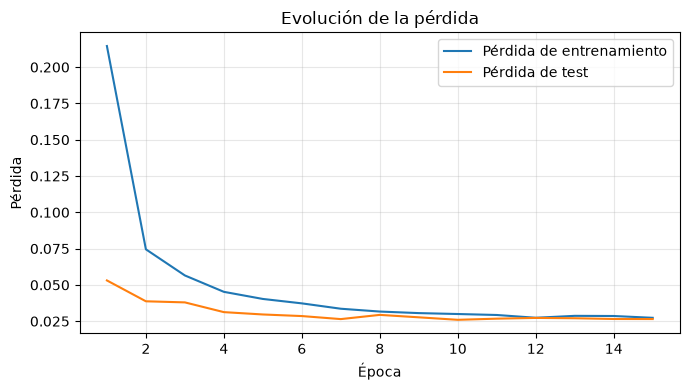

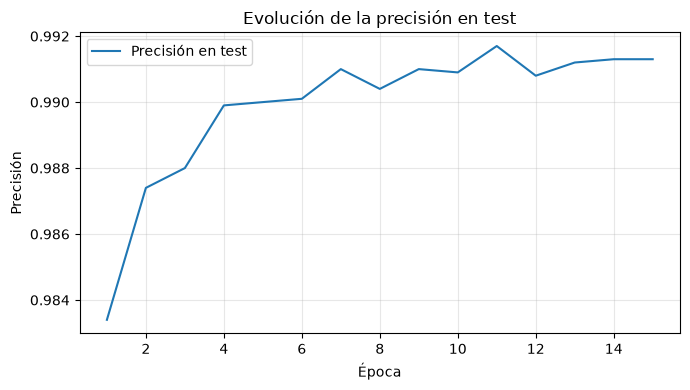

In [56]:
plt.figure(figsize=(7, 4))
plt.plot(history_df['epoch'], history_df['train_loss'], label='Pérdida de entrenamiento')
plt.plot(history_df['epoch'], history_df['test_loss'], label='Pérdida de test')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'curva_perdida.png', dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_df['epoch'], history_df['test_accuracy'], label='Precisión en test')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.title('Evolución de la precisión en test')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'curva_precision_test.png', dpi=150)
plt.show()

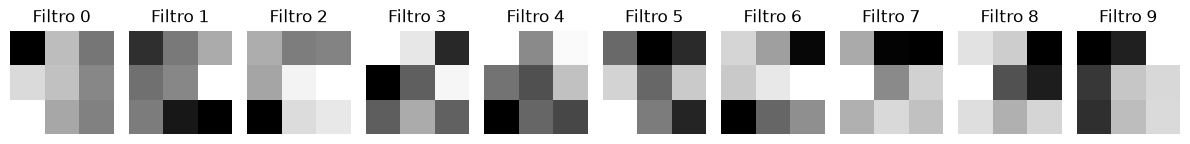

In [60]:
state_dict = modelo.state_dict()
conv1_filters = state_dict['conv1.weight'].detach().cpu()

num_filters_to_show = min(10, conv1_filters.shape[0])
plt.figure(figsize=(12, 2))
for i in range(num_filters_to_show):
    plt.subplot(1, num_filters_to_show, i + 1)
    plt.imshow(conv1_filters[i, 0].numpy(), cmap='gray')
    plt.title(f'Filtro {i}')
    plt.axis('off')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'filtros_conv1.png', dpi=150)
plt.show()

# Guardamos también los filtros como tensor para poder reutilizarlos.
torch.save(conv1_filters, OUTPUT_DIR / 'filtros_conv1.pt')

In [61]:
modelo.eval()
test_examples, test_labels = next(iter(test_dataloader))

with torch.no_grad():
    outputs = modelo(test_examples.to(DEVICE))
    predictions = outputs.argmax(dim=1).cpu()

results = pd.DataFrame({
    'indice': list(range(len(predictions))),
    'etiqueta_real': test_labels.numpy(),
    'prediccion': predictions.numpy(),
    'acierto': (predictions == test_labels).numpy(),
})
results.to_csv(OUTPUT_DIR / 'predicciones_muestra_test.csv', index=False)
results.head(10)

,indice,etiqueta_real,prediccion,acierto
0,0,7,7,True
1,1,2,2,True
2,2,1,1,True
3,3,0,0,True
4,4,4,4,True
5,5,1,1,True
6,6,4,4,True
7,7,9,9,True
8,8,5,5,True
9,9,9,9,True


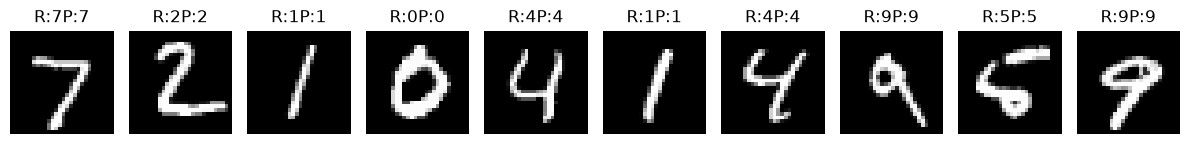

In [63]:
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(test_examples[i, 0], cmap='gray')
    plt.title(f'R:{test_labels[i].item()}P:{predictions[i].item()}')
    plt.axis('off')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'predicciones_ejemplos_test.png', dpi=150)
plt.show()

In [64]:
final_model_path = OUTPUT_DIR / 'modelo_mnist_convnet_deep_final.pt'
torch.save(modelo.state_dict(), final_model_path)
print(f'Modelo final guardado en: {final_model_path}')
print(f'Resultados guardados en: {OUTPUT_DIR.resolve()}')

Modelo final guardado en: resultados_mnist_convnet_deep\modelo_mnist_convnet_deep_final.pt
Resultados guardados en: F:\No sincronizar\Vision Artificial\Test\PLN\mnist\resultados_mnist_convnet_deep
